In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
sys.path.append(base_path)

import tensorflow as tf
from tensorflow.keras.callbacks import TensorBoard

import numpy as np
from tqdm import tqdm
import datetime
import matplotlib.pyplot as plt

from data_loaders.data_loader_complete import DataLoaderComplete
import project_images_loader as pil

import discriminator as Discriminator
import generator as Generator

import utils.functions as fc
import utils.visualization as vis
import utils.util_deep_learning as udl
import utils.util as util


2024-04-04 18:33:30.290199: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-04 18:33:30.290270: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-04 18:33:30.292048: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-04 18:33:30.302179: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-04-04 18:33:31.668313: W tensorflow/comp

## Visualize data

In [2]:
# %matplotlib widget


# data_train = DataLoader(batch_size=3, image_size=(193,229,193), shuffle=False, channels_first=True, image_sufix=pil.INAME_PREPROCESSED, nb_patients=-1)
# fc.imgshow_3D("", data_train[0][0][0,0])

### Validation visualization

In [3]:
def show_generated_image(id, G, img_size, current_plane=116):
    img_hunt3, _ = pil.load_preprocessed_image(3, id, absolute=True)
    img_hunt4, _ = pil.load_preprocessed_image(4, id, absolute=True)

    img_gen = G(udl.prepare_img_for_gan(img_hunt3, img_size), training=False)
    img_gen = udl.recover_img_from_gan(img_gen, img_hunt3.shape)
    return vis.shows_3_images(img_hunt3, img_hunt4, img_gen, current_plane=current_plane)



### Loss functions

In [4]:
cross_entropy = tf.keras.losses.BinaryCrossentropy()

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    total_loss = real_loss + fake_loss
    return total_loss

def generator_loss(fake_output, y_batch, y_batch_fake):
    gan_loss = cross_entropy(tf.ones_like(fake_output), fake_output)

    l1_loss = tf.reduce_mean(tf.abs(y_batch - y_batch_fake))
    total_loss = gan_loss + 50.0 * l1_loss

    return total_loss, gan_loss, l1_loss


In [5]:
# @tf.function
# def val_step(model, x_images, y_true, masks, class_centers, epoch):
#     y_pred, x_feat, x_gap = model(x_images, training=False)
#     x_weights = model.layers[-1].weights[0]
#     loss, loss_ce, loss_cskl, loss_cl, loss_cskl_mask = combined_loss(y_true, y_pred, x_feat, x_weights, masks, x_gap, class_centers, epoch)
#     return y_pred, loss, loss_ce, loss_cskl, loss_cl, loss_cskl_mask

@tf.function
def train_step(G, D, x_batch, y_batch, g_optimizer, d_optimizer):
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        y_batch_fake = G(x_batch, training=True)

        disc_output_real = D([x_batch, y_batch], training=True)
        disc_output_fake = D([x_batch, y_batch_fake], training=True)

        disc_loss = discriminator_loss(disc_output_real, disc_output_fake)
        gen_loss, gan_loss, l1_loss = generator_loss(disc_output_fake, y_batch, y_batch_fake)

    gradients_of_generator = gen_tape.gradient(gen_loss, G.trainable_variables)
    gradients_of_discriminator = disc_tape.gradient(disc_loss, D.trainable_variables)

    g_optimizer.apply_gradients(zip(gradients_of_generator, G.trainable_variables))
    d_optimizer.apply_gradients(zip(gradients_of_discriminator, D.trainable_variables))

    return disc_loss, gen_loss, gan_loss, l1_loss



### Training

Instructions for updating:
Call initializer instance with the dtype argument instead of passing it to the constructor


2024-04-04 18:33:35.397684: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1929] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14791 MB memory:  -> device: 0, name: Tesla V100-PCIE-16GB, pci bus id: 0000:3b:00.0, compute capability: 7.0



Epoch 1/50


2024-04-04 18:33:36.877838: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:454] Loaded cuDNN version 8904
2024-04-04 18:33:36.978543: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-04-04 18:33:37.529696: I external/local_tsl/tsl/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory


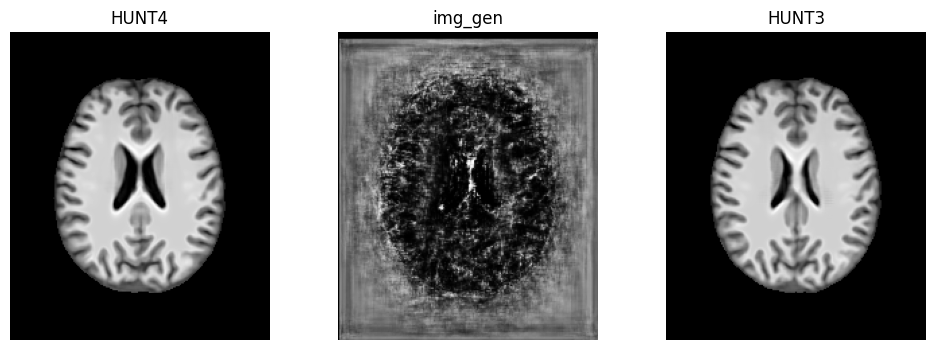

Initializing...:   0%|          | 0/300 [00:00<?, ?it/s]"`binary_crossentropy` received `from_logits=True`, but the `output` argument was produced by a Sigmoid activation and thus does not represent logits. Was this intended?
2024-04-04 18:34:22.786367: W external/local_tsl/tsl/framework/bfc_allocator.cc:485] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.46GiB (rounded to 2642411520)requested by op model_1/up_sampling3d_2/concat_2
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
2024-04-04 18:34:22.786419: I external/local_tsl/tsl/framework/bfc_allocator.cc:1039] BFCAllocator dump for GPU_0_bfc
2024-04-04 18:34:22.786431: I external/local_tsl/tsl/framework/bfc_allocator.cc:1046] Bin (256): 	Total Chunks: 142, Chunks in use: 140. 35.5KiB allocated for chunks. 35.0KiB in use in bin. 11.3KiB client-requested in use in b

ResourceExhaustedError: Graph execution error:

Detected at node model_1/up_sampling3d_2/concat_2 defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/traitlets/config/application.py", line 1075, in launch_instance

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 739, in start

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/site-packages/tornado/platform/asyncio.py", line 205, in start

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/asyncio/base_events.py", line 607, in run_forever

  File "/cluster/home/agustinc/miniconda3/envs/s4/lib/python3.11/asyncio/base_events.py", line 1922, in _run_once

  File

In [6]:

def train(num_epochs, batch_size):
    # input_shape = (193,229,193)
    input_shape = (192,224,192)

    # ---- Models
    D = Discriminator.create_discriminator_model(input_shape)
    G = Generator.create_generator_model(input_shape)

    # optimizers
    inital_lr = 1e-4
    g_optimizer = tf.keras.optimizers.Adam(inital_lr)
    d_optimizer = tf.keras.optimizers.Adam(inital_lr)
    
    g_optimizer_monitor = udl.LearningRateMonitor(g_optimizer, inital_lr, 0.5, 1e-7, 3, "loss")
    d_optimizer_monitor = udl.LearningRateMonitor(d_optimizer, inital_lr, 0.5, 1e-7, 3, "loss")
    
    # ---- Data
    server = True
    data_train = DataLoaderComplete(image_sufix=pil.INAME_PREPROCESSED,
                                    batch_size=batch_size, 
                                    image_size=input_shape, 
                                    channels_first=False,
                                    shuffle=True, 
                                    nb_patients=300, 
                                    shuffle_before_selecting=False, 
                                    server=server)
    # visualization
    nb_loss = 4
    acum_loss_train = udl.AcumulativeMetrics(nb_metrics = nb_loss)

    log_dir=f"{current_path}/models/logs/train"
    summary_writer = tf.summary.create_file_writer(log_dir)


    # ---- checkpoint
    checkpoint_dir = f"{current_path}/models/training_checkpoints/"
    checkpoint_prefix = os.path.join(checkpoint_dir, "ckpt")
    checkpoint = tf.train.Checkpoint(generator_optimizer=g_optimizer,
                                    discriminator_optimizer=d_optimizer,
                                    generator=G,
                                    discriminator=D)
    checkpoint.restore(tf.train.latest_checkpoint(checkpoint_dir))

    for epoch in range(0,num_epochs):

        print(f"\nEpoch {epoch+1}/{num_epochs}")
        
        # visualize images
        val_results = show_generated_image("08202", G, input_shape, current_plane=116)

        # ---- Train
        acum_loss_train.reset()
        progress_bar = tqdm(total=len(data_train), desc=f'Initializing...')
        for step, (x_batch, y_batch) in enumerate(data_train):
            disc_loss, gen_loss, gan_loss, l1_loss = train_step(G, D, x_batch, y_batch, g_optimizer, d_optimizer)
            acum_loss_train.update((gen_loss, disc_loss, gan_loss, l1_loss))
            losses_text = acum_loss_train.get_progress_bar_text(['disc_loss', 'gen_loss', 'gan_loss', 'l1_loss'])
            
            progress_bar.set_description(desc=losses_text)
            progress_bar.update(1)
        del progress_bar

        # ---- Check points
        if  epoch > 0 and epoch % 2 == 0:
            checkpoint.save(file_prefix=checkpoint_prefix)
        
        # ---- Learning rate
        d_optimizer_monitor.on_epoch_end(loss_mean[0])
        g_optimizer_monitor.on_epoch_end(loss_mean[1])

        # ---- tensorboard
        loss_mean = acum_loss_train.get_mean()
        with summary_writer.as_default():
            tf.summary.scalar('discriminator_loss', loss_mean[0], step=epoch)
            tf.summary.scalar('generator_loss', loss_mean[1], step=epoch)
            tf.summary.scalar('gan_loss', loss_mean[2], step=epoch)
            tf.summary.scalar('l1_loss', loss_mean[3], step=epoch)
        
            # images
            gen_image = np.expand_dims(np.expand_dims(val_results[2], axis=-1), axis=0)
            hunt4_vs_gen = np.expand_dims(np.stack([val_results[2], val_results[1], np.zeros_like(val_results[1])], axis=-1), axis=0)
            tf.summary.image("generated", gen_image, step=epoch)
            tf.summary.image("R: Gen - G: HUNT4", hunt4_vs_gen, step=epoch)
    



train(num_epochs=50, batch_size=1)

In [ ]:
# Sim: 0.00000 	 gen_loss: 0.93415 	 disc_loss: 1.11709: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]
# Sim: 0.00000 	 gen_loss: 1.22538 	 disc_loss: 1.64933: 100%|██████████| 8/8 [00:14<00:00,  1.86s/it]